### Gradientenabstieg

Im Notebook Perzeptron und Neuron haben wir gesehen: Ein Neuron mit Sigmoid gibt Werte zwischen 0 und 1 aus, und
kleine Änderungen an den Parametern ändern die Ausgabe ein wenig. Jetzt soll das Neuron seine Parameter selbst
finden. Dafür brauchen wir zwei Dinge:

1. eine Zahl, die misst, wie schlecht das Neuron gerade ist: den **Fehler**,
2. ein Verfahren, das die Parameter Schritt für Schritt so ändert, dass der Fehler kleiner wird: den
   **Gradientenabstieg**.

Als Beispiel nehmen wir wieder ein Neuron, das OR lernen soll, mit schlechten Startwerten.

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np

def sigmoid(z):
    return 1 / (1 + math.exp(-z))

def neuron(x1, x2, w1, w2, b):
    return sigmoid(w1 * x1 + w2 * x2 + b)

X = [(0, 0), (0, 1), (1, 0), (1, 1)]
Y_or = [0, 1, 1, 1]

w1, w2, b = -1, 1, -1.5
for (x1, x2), y in zip(X, Y_or):
    print(x1, x2, '  Neuron:', round(neuron(x1, x2, w1, w2, b), 4), '  OR:', y)

0 0   Neuron: 0.1824   OR: 0
0 1   Neuron: 0.3775   OR: 1
1 0   Neuron: 0.0759   OR: 1
1 1   Neuron: 0.1824   OR: 1


### Den Fehler messen: Binary Cross-Entropy

Um zu lernen, braucht das Netz eine Zahl, die angibt, wie schlecht es gerade ist: den **Fehler** $L$ (loss). Wir
bauen die Formel in vier Schritten auf.

**1. Welche Wahrscheinlichkeit gibt das Netz der richtigen Klasse?** Das Ausgabeneuron liefert $\hat{y}$, die
Wahrscheinlichkeit für die Klasse 1. Für die Klasse 0 bleibt dann $1 - \hat{y}$. Ist $y$ die richtige Klasse, so ist
die Wahrscheinlichkeit $p$, die das Netz der richtigen Klasse gibt:

| $\hat{y}$ | richtige Klasse $y$ | $p$ | Bewertung |
|---|---|---|---|
| 0.9 | 1 | 0.9 | gut |
| 0.9 | 0 | 0.1 | schlecht: sicher und falsch |
| 0.3 | 0 | 0.7 | ganz gut |
| 0.5 | 0 oder 1 | 0.5 | das Netz rät |

Ein gutes Netz gibt bei allen Trainingsbeispielen der richtigen Klasse eine Wahrscheinlichkeit nahe 1.

**2. Mehrere Beispiele: Wahrscheinlichkeiten multiplizieren.** Stell dir vor, das Netz würfelt seine Antwort mit
diesen Wahrscheinlichkeiten aus. Die Wahrscheinlichkeit, dass es bei **allen** Beispielen richtig antwortet, ist nach
der Pfadregel das Produkt der einzelnen $p$. Je größer dieses Produkt, desto besser das Netz.

Zwei Netze bei drei Beispielen. Netz A ist bei zwei Beispielen sehr sicher richtig, beim dritten sehr sicher falsch.
Netz B ist bei allen dreien nur mäßig sicher, aber immer richtig:

In [2]:
p_A = [0.9, 0.9, 0.1]
p_B = [0.6, 0.6, 0.6]
print(round(math.prod(p_A), 4), round(math.prod(p_B), 4))

0.081 0.216


Netz B hat das größere Produkt, es ist das bessere Netz.

**3. Der Logarithmus macht aus dem Produkt eine Summe.** Mit dem Produkt kann man schlecht rechnen. Bei vielen
Beispielen wird es winzig, schon 1000 Beispiele mit $p = 0.9$ ergeben $0.9^{1000} \approx 1.7 \cdot 10^{-46}$. Und
Ableitungen von langen Produkten sind mühsam. Deshalb nimmt man den natürlichen Logarithmus. Nach dem
Logarithmengesetz gilt

$$\ln(p_1 \cdot p_2 \cdot p_3) = \ln(p_1) + \ln(p_2) + \ln(p_3)$$

Der Logarithmus ist streng monoton steigend: Ein größeres Produkt hat auch einen größeren Logarithmus. Weil alle
$p \le 1$ sind, sind die Logarithmen negativ oder 0. Mit einem Minus davor werden sie positiv, und aus „möglichst
groß“ wird „möglichst klein“. So erhalten wir den Fehler für ein einzelnes Beispiel:

$$L = -\ln(p)$$

Der Gesamtfehler ist die Summe (oder der Mittelwert) dieser Fehler. Ein großes Produkt bedeutet einen kleinen
Gesamtfehler.

In [3]:
print(0.9 ** 1000)
fehler_A = [-math.log(p) for p in p_A]
fehler_B = [-math.log(p) for p in p_B]
print([round(f, 4) for f in fehler_A], round(sum(fehler_A), 4), round(-math.log(math.prod(p_A)), 4))
print([round(f, 4) for f in fehler_B], round(sum(fehler_B), 4), round(-math.log(math.prod(p_B)), 4))

1.7478712517226947e-46
[0.1054, 0.1054, 2.3026] 2.5133 2.5133
[0.5108, 0.5108, 0.5108] 1.5325 1.5325


Die Summe der Einzelfehler ist gleich $-\ln$ des Produkts, und Netz B hat den kleineren Fehler.

Wie sieht $-\ln(p)$ aus? Zum Vergleich ist der einfache Abstand $1 - p$ zur 1 mit eingezeichnet:

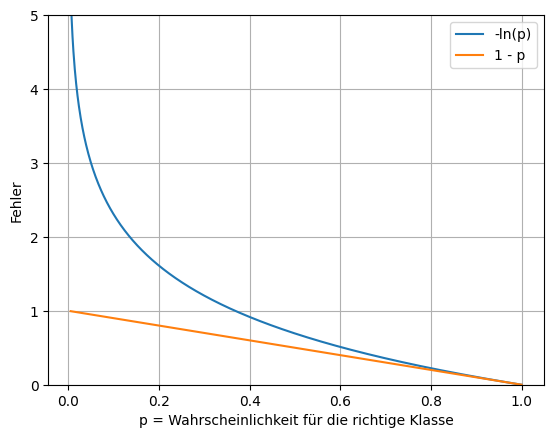

In [4]:
import matplotlib.pyplot as plt

p = [i / 1000 for i in range(5, 1001)]
plt.plot(p, [-math.log(t) for t in p], label='-ln(p)')
plt.plot(p, [1 - t for t in p], label='1 - p')
plt.xlabel('p = Wahrscheinlichkeit für die richtige Klasse')
plt.ylabel('Fehler')
plt.ylim(0, 5)
plt.legend()
plt.grid()
plt.show()

Bei $p = 1$ sind beide Fehler 0. Je kleiner $p$ wird, desto steiler steigt $-\ln(p)$ an, bei $p \to 0$ geht der
Fehler gegen unendlich. Eine Antwort, die sicher und falsch ist, wird also sehr hart bestraft. Der einfache Abstand
$1 - p$ ist dagegen höchstens 1.

Das macht bei unseren beiden Netzen den Unterschied:

In [5]:
print('Abstand:  A', round(sum(1 - p for p in p_A), 4), ' B', round(sum(1 - p for p in p_B), 4))
print('-ln(p):   A', round(sum(fehler_A), 4), ' B', round(sum(fehler_B), 4))

Abstand:  A 1.1  B 1.2
-ln(p):   A 2.5133  B 1.5325


Nach dem Abstand wäre Netz A besser, nach $-\ln(p)$ ist es Netz B, so wie beim Produkt der Wahrscheinlichkeiten.
Der Abstand übersieht, dass sich Netz A beim dritten Beispiel fast sicher ist und trotzdem falsch liegt.

**4. Eine Formel für beide Klassen.** Für $y = 1$ ist $p = \hat{y}$, für $y = 0$ ist $p = 1 - \hat{y}$. Weil $y$ nur 0
oder 1 sein kann, kann man beide Fälle in eine Formel schreiben:

$$L = -\big(y \ln(\hat{y}) + (1 - y)\ln(1 - \hat{y})\big)$$

$y$ wirkt dabei wie ein Schalter:

| $y$ | eingesetzt | Fehler |
|---|---|---|
| 1 | $-\big(1 \cdot \ln(\hat{y}) + 0 \cdot \ln(1 - \hat{y})\big)$ | $-\ln(\hat{y})$ |
| 0 | $-\big(0 \cdot \ln(\hat{y}) + 1 \cdot \ln(1 - \hat{y})\big)$ | $-\ln(1 - \hat{y})$ |

Die Formel sieht kompliziert aus, sagt aber nur: **Der Fehler ist der negative Logarithmus der Wahrscheinlichkeit,
die das Netz der richtigen Klasse gibt.** Sie heißt **Binary Cross-Entropy**, „binary“ wegen der zwei Klassen. Der
Name Cross-Entropy kommt aus der Informationstheorie und spielt für uns keine Rolle.

In [6]:
def bce(yh, y):
    return -(y * math.log(yh) + (1 - y) * math.log(1 - yh))

print('yh      y=1     y=0')
for yh in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(yh, '  ', round(bce(yh, 1), 4), '  ', round(bce(yh, 0), 4))

yh      y=1     y=0
0.99    0.0101    4.6052
0.9    0.1054    2.3026
0.5    0.6931    0.6931
0.1    2.3026    0.1054
0.01    4.6052    0.0101


Gibt das Netz der richtigen Klasse die Wahrscheinlichkeit 0.99, ist der Fehler fast 0. Bei 0.5 (das Netz rät) ist er
$\ln 2 \approx 0.6931$. Je sicherer sich das Netz bei einer falschen Antwort ist, desto größer wird der Fehler. Im
Notebook Backpropagation sehen wir einen weiteren Vorteil: Zusammen mit der Sigmoidfunktion wird die Ableitung sehr
einfach.

#### Der Fehler des Neurons für OR

Der Fehler des Neurons ist der Mittelwert der Fehler für die vier Beispiele:

In [7]:
def fehler(w1, w2, b, X, Y):
    return sum(bce(neuron(x1, x2, w1, w2, b), y) for (x1, x2), y in zip(X, Y)) / len(X)

print(round(fehler(-1, 1, -1.5, X, Y_or), 4))
print(round(fehler(-1.1, 1, -1.5, X, Y_or), 4))
print(round(fehler(-0.9, 1, -1.5, X, Y_or), 4))

1.3639
1.4078
1.3207


Mit den Startwerten ist der Fehler 1.3639. Wird $w_1$ etwas kleiner, steigt er auf 1.4078, wird $w_1$ etwas größer,
sinkt er auf 1.3207. Jetzt haben wir eine Zahl, an der wir ablesen können, ob eine Änderung hilft.

### Die Ableitung zeigt die Richtung

Wir halten $w_2$ und $b$ fest und betrachten den Fehler nur als Funktion von $w_1$:

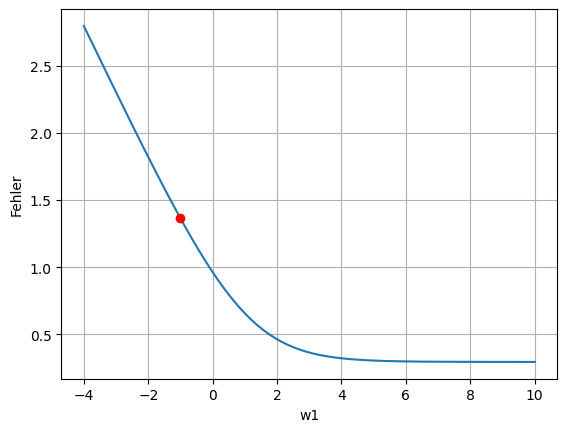

In [8]:
def L(w1):
    return fehler(w1, 1, -1.5, X, Y_or)

ws = np.linspace(-4, 10, 300)
plt.plot(ws, [L(w) for w in ws])
plt.scatter([-1], [L(-1)], color='red', zorder=3)
plt.xlabel('w1')
plt.ylabel('Fehler')
plt.grid()
plt.show()

Der rote Punkt ist unser $w_1 = -1$. Die Kurve fällt dort, also sollten wir $w_1$ vergrößern. Wie steil sie fällt,
gibt die **Ableitung** an, die Steigung der Tangente. Wir berechnen sie **numerisch**: Wir verändern $w_1$ um eine
kleine Zahl $h$ nach oben und nach unten und teilen die Änderung des Fehlers durch $2h$:

$$L'(w_1) \approx \frac{L(w_1 + h) - L(w_1 - h)}{2h}$$

In [9]:
def ableitung(f, x, h=0.0001):
    return (f(x + h) - f(x - h)) / (2 * h)

print(round(ableitung(L, -1), 4))

-0.4354


Die Ableitung ist negativ: Wird $w_1$ größer, wird der Fehler kleiner, und zwar ungefähr um das 0.4354-Fache der
Änderung. Die Ableitung sagt also beides: in welche Richtung wir gehen sollen (gegen ihr Vorzeichen) und wie stark der
Fehler auf den Parameter reagiert.

### Gradientenabstieg mit einem Parameter

Der **Gradientenabstieg** geht immer ein Stück gegen die Ableitung:

$$x_{neu} = x - lr \cdot f'(x)$$

Ist die Ableitung positiv (die Kurve steigt), wird $x$ kleiner. Ist sie negativ, wird $x$ größer. Die **Lernrate**
$lr$ legt die Schrittweite fest. Weil die Ableitung nahe am Minimum klein wird, werden dort auch die Schritte klein.

Ein einfaches Beispiel: $f(x) = (x - 3)^2 + 1$ hat das Minimum bei $x = 3$. Die Ableitung ist $f'(x) = 2(x - 3)$. Wir
starten bei $x = 0$ mit $lr = 0.25$:

In [10]:
def f(x):
    return (x - 3) ** 2 + 1

def f_strich(x):
    return 2 * (x - 3)

x = 0
lr = 0.25
weg = [x]
for schritt in range(6):
    x = x - lr * f_strich(x)
    weg.append(x)
    print(schritt + 1, x, f(x))

1 1.5 3.25
2 2.25 1.5625
3 2.625 1.140625
4 2.8125 1.03515625
5 2.90625 1.0087890625
6 2.953125 1.002197265625


Erster Schritt: $f'(0) = -6$, also $x = 0 - 0.25 \cdot (-6) = 1.5$. Zweiter Schritt: $f'(1.5) = -3$, also
$x = 1.5 + 0.75 = 2.25$. Mit jedem Schritt halbiert sich der Abstand zum Minimum.

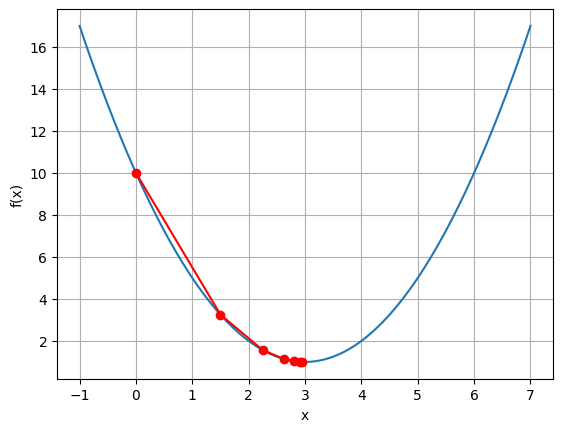

In [11]:
xs = np.linspace(-1, 7, 200)
plt.plot(xs, (xs - 3) ** 2 + 1)
plt.plot(weg, [f(x) for x in weg], 'o-', color='red')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.show()

#### Die Wahl der Lernrate

Wir vergleichen verschiedene Lernraten, jeweils 10 Schritte ab $x = 0$:

In [12]:
for lr in [0.05, 0.25, 0.9, 1.1]:
    x = 0
    werte = []
    for schritt in range(10):
        x = x - lr * f_strich(x)
        werte.append(round(x, 2))
    print(lr, werte)

0.05 [0.3, 0.57, 0.81, 1.03, 1.23, 1.41, 1.57, 1.71, 1.84, 1.95]
0.25 [1.5, 2.25, 2.62, 2.81, 2.91, 2.95, 2.98, 2.99, 2.99, 3.0]
0.9 [5.4, 1.08, 4.54, 1.77, 3.98, 2.21, 3.63, 2.5, 3.4, 2.68]
1.1 [6.6, -1.32, 8.18, -3.22, 10.46, -5.96, 13.75, -9.9, 18.48, -15.58]


- $lr = 0.05$: Die Schritte sind klein, nach 10 Schritten sind wir erst bei 1.95.
- $lr = 0.25$: schnell und ruhig.
- $lr = 0.9$: Jeder Schritt springt über das Minimum hinaus auf die andere Seite. Weil der Abstand trotzdem kleiner
  wird, kommen wir langsam an.
- $lr = 1.1$: Die Sprünge werden immer größer, der Gradientenabstieg läuft weg.

Eine zu kleine Lernrate macht das Lernen langsam, eine zu große macht es unruhig oder lässt es scheitern.

### Mehrere Parameter: der Gradient

Ein Neuron hat mehrere Parameter. Für jeden berechnen wir eine Ableitung, wobei wir die anderen festhalten. Das
nennt man **partielle Ableitung**, geschrieben $\frac{\partial f}{\partial x_1}$. Alle partiellen Ableitungen
zusammen bilden den **Gradienten**.

Beispiel: $f(x_1, x_2) = x_1^2 + 3 x_2^2$. Hält man $x_2$ fest, ist $\frac{\partial f}{\partial x_1} = 2 x_1$. Hält man
$x_1$ fest, ist $\frac{\partial f}{\partial x_2} = 6 x_2$. An der Stelle $(2, 1)$ ist der Gradient $(4, 6)$.

Der Gradient zeigt in die Richtung, in der $f$ am steilsten ansteigt. Der Gradientenabstieg geht in die
Gegenrichtung, für alle Parameter gleichzeitig:

$$x_1 \leftarrow x_1 - lr \cdot \frac{\partial f}{\partial x_1}, \qquad x_2 \leftarrow x_2 - lr \cdot \frac{\partial f}{\partial x_2}$$

Den Gradienten können wir wieder numerisch berechnen. Die Funktion bekommt die Parameter als Liste:

In [13]:
def gradient(f, p, h=0.0001):
    g = []
    for i in range(len(p)):
        plus = p[:]
        minus = p[:]
        plus[i] += h
        minus[i] -= h
        g.append((f(plus) - f(minus)) / (2 * h))
    return g

def f2(p):
    return p[0] ** 2 + 3 * p[1] ** 2

print([round(g, 4) for g in gradient(f2, [2, 1])])

[4.0, 6.0]


[1.6, 0.4] [1.28, 0.16] [0.0704, 0.0]


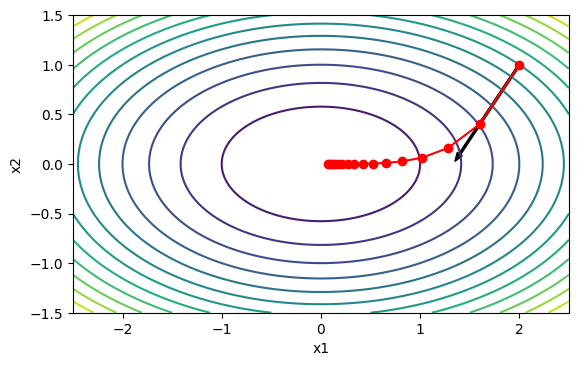

In [14]:
p = [2, 1]
weg = [p]
for schritt in range(15):
    g = gradient(f2, p)
    p = [p[i] - 0.1 * g[i] for i in range(2)]
    weg.append(p)
print([round(v, 4) for v in weg[1]], [round(v, 4) for v in weg[2]], [round(v, 4) for v in weg[-1]])

g1, g2 = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-1.5, 1.5, 200))
plt.contour(g1, g2, g1 ** 2 + 3 * g2 ** 2, levels=15)
plt.plot([q[0] for q in weg], [q[1] for q in weg], 'o-', color='red')
plt.arrow(2, 1, -0.15 * 4, -0.15 * 6, width=0.02, color='black')
plt.gca().set_aspect('equal')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

Die Linien verbinden Punkte mit gleichem Funktionswert (**Höhenlinien**), wie auf einer Wanderkarte. Der schwarze
Pfeil zeigt in Richtung des negativen Gradienten, er steht senkrecht auf der Höhenlinie. Der Weg (rot) führt in das
Minimum bei $(0, 0)$: nach dem ersten Schritt $(1.6, 0.4)$, nach dem zweiten $(1.28, 0.16)$. In $x_2$-Richtung ist
die Funktion steiler, deshalb geht es dort zuerst schneller.

### Ein Neuron lernt OR

Jetzt wenden wir den Gradientenabstieg auf das Neuron an. Die Parameter sind $p = (w_1, w_2, b)$, die Funktion ist
der mittlere Fehler über alle vier Beispiele. Ein Schritt über alle Beispiele heißt **Epoche**.

In [15]:
def fehler_or(p):
    return fehler(p[0], p[1], p[2], X, Y_or)

p = [-1, 1, -1.5]
print('Gradient am Start:', [round(g, 4) for g in gradient(fehler_or, p)])

Gradient am Start: [-0.4354, -0.36, -0.5454]


Alle drei partiellen Ableitungen sind negativ, also werden im ersten Schritt alle drei Parameter größer.

In [16]:
def trainieren(fehlerfunktion, p, lr, epochen):
    verlauf = []
    for epoche in range(epochen):
        verlauf.append(fehlerfunktion(p))
        g = gradient(fehlerfunktion, p)
        p = [p[i] - lr * g[i] for i in range(len(p))]
    return p, verlauf

p, verlauf = trainieren(fehler_or, [-1, 1, -1.5], 1, 500)
print('Parameter:', [round(v, 2) for v in p])
print('Fehler:', round(verlauf[0], 4), round(verlauf[10], 4), round(verlauf[100], 4), round(verlauf[-1], 4))
for (x1, x2), y in zip(X, Y_or):
    print(x1, x2, '  Neuron:', round(neuron(x1, x2, *p), 4), '  OR:', y)

Parameter: [7.27, 7.28, -3.16]
Fehler: 1.3639 0.2948 0.0835 0.0185
0 0   Neuron: 0.0405   OR: 0
0 1   Neuron: 0.9839   OR: 1
1 0   Neuron: 0.9838   OR: 1
1 1   Neuron: 1.0   OR: 1


Nach 500 Epochen ist der Fehler von 1.3639 auf 0.0185 gesunken. Das Neuron gibt bei $(0, 0)$ etwa 0.04 aus, sonst
fast 1. Gelernt hat es $w_1 \approx w_2 \approx 7.3$ und $b \approx -3.2$.

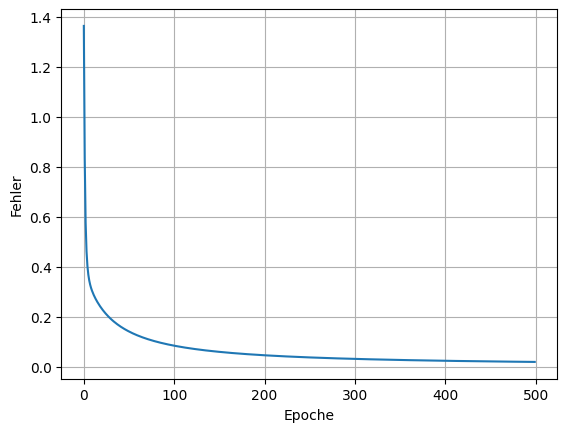

In [17]:
plt.plot(verlauf)
plt.xlabel('Epoche')
plt.ylabel('Fehler')
plt.grid()
plt.show()

#### Die Lernrate beim Neuron

Dasselbe Training mit drei Lernraten:

0.05 [1.364, 1.333, 1.303, 1.09, 0.389]
1 [1.364, 0.832, 0.576, 0.295, 0.084]
20 [1.364, 2.352, 1.105, 0.012, 0.004]


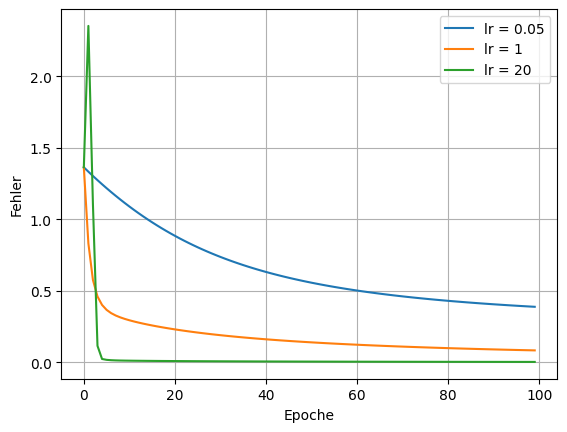

In [18]:
for lr in [0.05, 1, 20]:
    p, verlauf = trainieren(fehler_or, [-1, 1, -1.5], lr, 100)
    plt.plot(verlauf, label=f'lr = {lr}')
    print(lr, [round(verlauf[i], 3) for i in [0, 1, 2, 10, 99]])
plt.xlabel('Epoche')
plt.ylabel('Fehler')
plt.legend()
plt.grid()
plt.show()

Mit $lr = 0.05$ sinkt der Fehler sehr langsam. Mit $lr = 20$ springt er im ersten Schritt sogar nach oben (von 1.364
auf 2.352), weil der Schritt viel zu groß ist, danach geht es aber schnell nach unten. Eine passende Lernrate muss man
ausprobieren. Große Netze benutzen deshalb oft Verfahren, die die Lernrate während des Trainings anpassen (mehr dazu
im Notebook zu PyTorch).

### XOR: Ein Neuron schafft es nicht

Wir trainieren dasselbe Neuron auf XOR:

In [19]:
Y_xor = [0, 1, 1, 0]

def fehler_xor(p):
    return fehler(p[0], p[1], p[2], X, Y_xor)

p, verlauf = trainieren(fehler_xor, [-1, 1, -1.5], 1, 2000)
print('Parameter:', [round(v, 4) for v in p], '  Fehler:', round(verlauf[-1], 4))
for (x1, x2), y in zip(X, Y_xor):
    print(x1, x2, '  Neuron:', round(neuron(x1, x2, *p), 4), '  XOR:', y)

Parameter: [0.0, 0.0, -0.0]   Fehler: 0.6931
0 0   Neuron: 0.5   XOR: 0
0 1   Neuron: 0.5   XOR: 1
1 0   Neuron: 0.5   XOR: 1
1 1   Neuron: 0.5   XOR: 0


Alle Parameter gehen gegen 0, das Neuron gibt überall 0.5 aus, der Fehler bleibt bei $\ln 2 \approx 0.6931$. Das
Neuron kann nur eine Trenngerade ziehen, und für XOR gibt es keine. Das Beste, was es tun kann, ist raten.

Für XOR braucht man ein Netz mit einer versteckten Schicht. Den Gradienten könnte man auch dort numerisch
berechnen. Das kostet aber für jeden Parameter zwei Berechnungen des Fehlers über alle Trainingsbeispiele. Ein
kleines Netz zur Bilderkennung hat schon über 100000 Parameter. Im nächsten Notebook lernen wir
**Backpropagation** kennen: Damit bekommt man alle Ableitungen auf einmal, mit einem Durchgang rückwärts durch das
Netz.

### Lokale Minima

Der Gradientenabstieg geht immer bergab. Hat der Fehler mehrere Täler, landet er in dem Tal, in dem er angefangen
hat. Beispiel: $f(x) = x^4 - 3x^2 + x$.

Start 2   Ende 1.1309   g = -1.0702
Start -2   Ende -1.3008   g = -3.5139


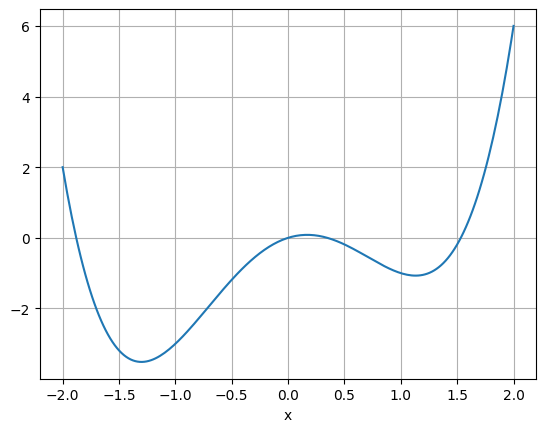

In [20]:
def g(x):
    return x ** 4 - 3 * x ** 2 + x

def g_strich(x):
    return 4 * x ** 3 - 6 * x + 1

for start in [2, -2]:
    x = start
    for schritt in range(200):
        x = x - 0.01 * g_strich(x)
    print('Start', start, '  Ende', round(x, 4), '  g =', round(g(x), 4))

xs = np.linspace(-2, 2, 200)
plt.plot(xs, xs ** 4 - 3 * xs ** 2 + xs)
plt.xlabel('x')
plt.grid()
plt.show()

Von $x = 2$ aus endet der Gradientenabstieg im rechten Tal bei $x \approx 1.13$ mit $g \approx -1.07$. Von $x = -2$ aus
findet er das tiefere linke Tal bei $x \approx -1.30$ mit $g \approx -3.51$. Das rechte Tal ist nur ein **lokales
Minimum**. Bei neuronalen Netzen startet man deshalb mit zufälligen Parametern und trainiert manchmal mehrmals. In
der Praxis findet der Gradientenabstieg in großen Netzen trotzdem meist gute Lösungen.

### Zusammenfassung

- Der **Fehler** misst, wie schlecht ein Netz ist. Bei zwei Klassen nimmt man die **Binary Cross-Entropy**: den
  negativen Logarithmus der Wahrscheinlichkeit, die das Netz der richtigen Klasse gibt, gemittelt über alle
  Beispiele.
- Die **Ableitung** des Fehlers nach einem Parameter sagt, in welche Richtung und wie stark sich der Fehler ändert,
  wenn man den Parameter vergrößert. Man kann sie numerisch berechnen.
- Der **Gradient** ist die Liste aller partiellen Ableitungen. Er zeigt in Richtung des steilsten Anstiegs.
- **Gradientenabstieg:** Jeder Parameter wird ein Stück gegen seine Ableitung verschoben,
  $p_{neu} = p - lr \cdot \frac{\partial L}{\partial p}$. Die **Lernrate** bestimmt die Schrittweite.
- Ein einzelnes Neuron lernt so OR, aber nicht XOR. Für Netze braucht man eine schnellere Art, den Gradienten zu
  berechnen: Backpropagation.